[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/05_HistGradientBoosting_and_LightGBM.ipynb)

# 05. Boosting: HistGradientBoosting and LightGBM
**Run on:** Laptop B · **Approx. runtime:** ~4-6 min on a 4-core laptop


**Protocol (same for every model):**
- Each row is one *(GPS point, candidate arc)* pair. The label is 1 if the arc is the point's reference arc.
- **5-fold GroupKFold by trip** on the 78 usable training trips. Each fold fits on a 300k-row sample of points (KNN uses 100k) and is scored on all candidates of the held-out trips.
- The model is then **refit on the training split** and scored on the **10 student-test trips**.
- **Metrics:**
  - macro F1 / precision / recall: candidate level, threshold 0.5
  - log loss
  - **Top-1 accuracy**: the share of GPS points whose highest-scoring candidate is the reference arc
  - continuity
- The **HMM/Viterbi** decoder (parameters in `models/hmm_params.json`) is then run on this model's probabilities to compare *classifier only* with *classifier + HMM*.


**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [ ]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


In [2]:
tr, tr_pts, te, te_pts = nb.load_data()

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows


## HistGradientBoosting


**What it does:** gradient boosting. Trees are added **one after another**, each fitted to the errors (gradients of the log loss) of the current ensemble. Features are binned into histograms for speed.
- **Why:** boosting is usually the strongest family on tabular features like ours.
- **Limitation:** sequential training; more hyperparameters to tune.
- **Hyperparameters:** max_iter = 300, learning_rate = 0.1, max_leaf_nodes = 31, automatic early stopping.
- **Loss:** binary log loss.

In [3]:
make_histgb = lambda: make_model("histgb", SEED)
print(make_histgb())
cv_histgb = nb.run_cv(make_histgb, tr, tr_pts, max_rows=300000)
cv_histgb.round(4)

HistGradientBoostingClassifier(max_iter=300, random_state=42)


  fold 0: F1=0.9163 top1=0.8634 ll=0.1373


  fold 1: F1=0.9318 top1=0.8835 ll=0.0985


  fold 2: F1=0.9214 top1=0.8784 ll=0.1376


  fold 3: F1=0.9507 top1=0.9251 ll=0.0772


  fold 4: F1=0.9148 top1=0.8603 ll=0.1221


CV time 179s | mean macro F1 0.9270 ± 0.0148


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.9163,0.8759,0.8502,0.1373,0.8634,0.9899,0.0261,32.9707
1,0.9318,0.9024,0.8656,0.0985,0.8835,1.0366,0.0333,25.0466
2,0.9214,0.8667,0.8856,0.1376,0.8784,2.1546,0.0498,28.8753
3,0.9507,0.9262,0.9099,0.0772,0.9251,2.0489,0.0595,72.2190
4,0.9148,0.8778,0.8368,0.1221,0.8603,1.0577,0.0311,10.5337


In [4]:
model_histgb, train_histgb, test_histgb, p_histgb = nb.fit_and_evaluate(make_histgb, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_histgb['continuity']:.4f} | inference {test_histgb['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("HistGradientBoosting", cv_histgb, train_histgb, test_histgb)

fit 38.5s on 300,108 rows
student-test continuity (classifier only): 0.9285 | inference 0.0426 ms/point


HistGradientBoosting,train (fit sample),CV mean (5 folds),student test
macro F1,0.9363,0.9270,0.9241
precision,0.8995,0.8898,0.8769
recall,0.8901,0.8696,0.8701
log loss,0.0939,0.1145,0.1079
Top-1 accuracy,0.8986,0.8821,0.8796


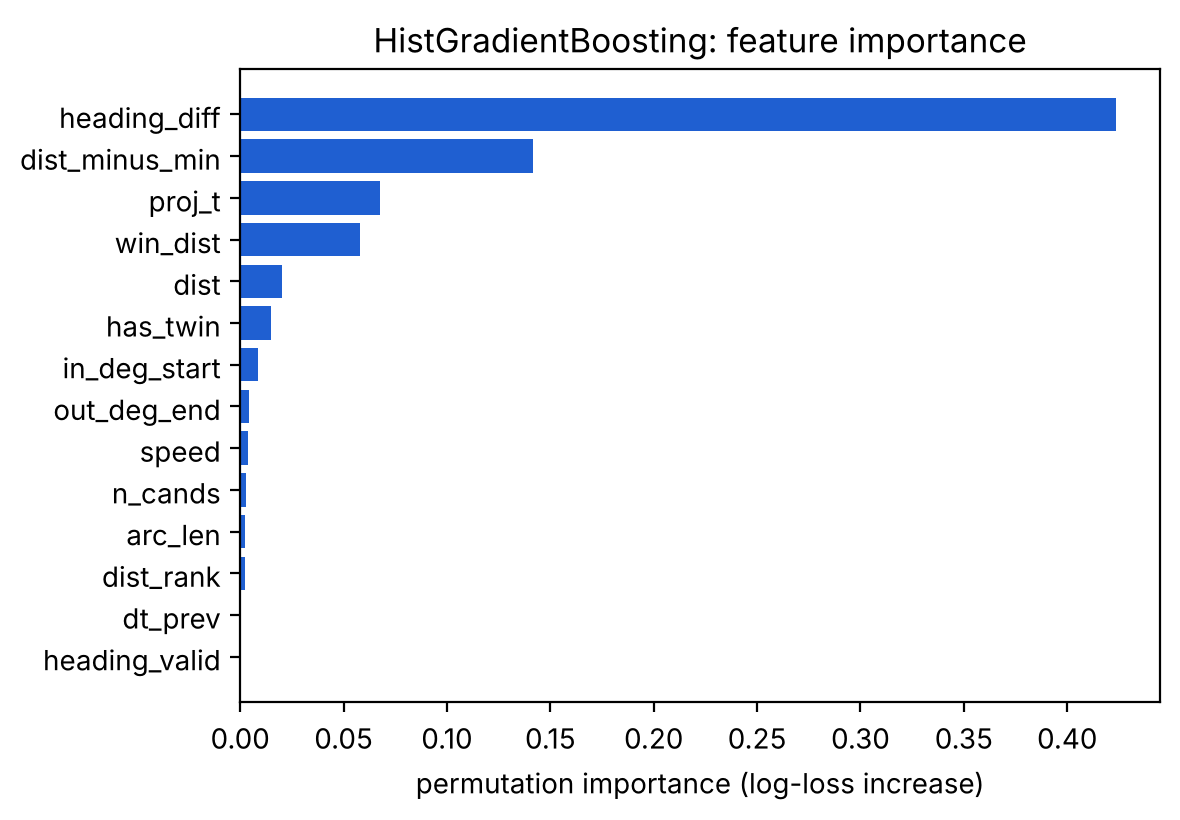

In [5]:
imp_histgb = nb.plot_importance(model_histgb, te, "HistGradientBoosting")

HistGradientBoosting: mean over 10 trips
cls_top1          0.8964
hmm_top1          0.9492
cls_route_f1      0.7766
hmm_route_f1      0.9579
cls_continuity    0.9285
hmm_continuity    0.9781


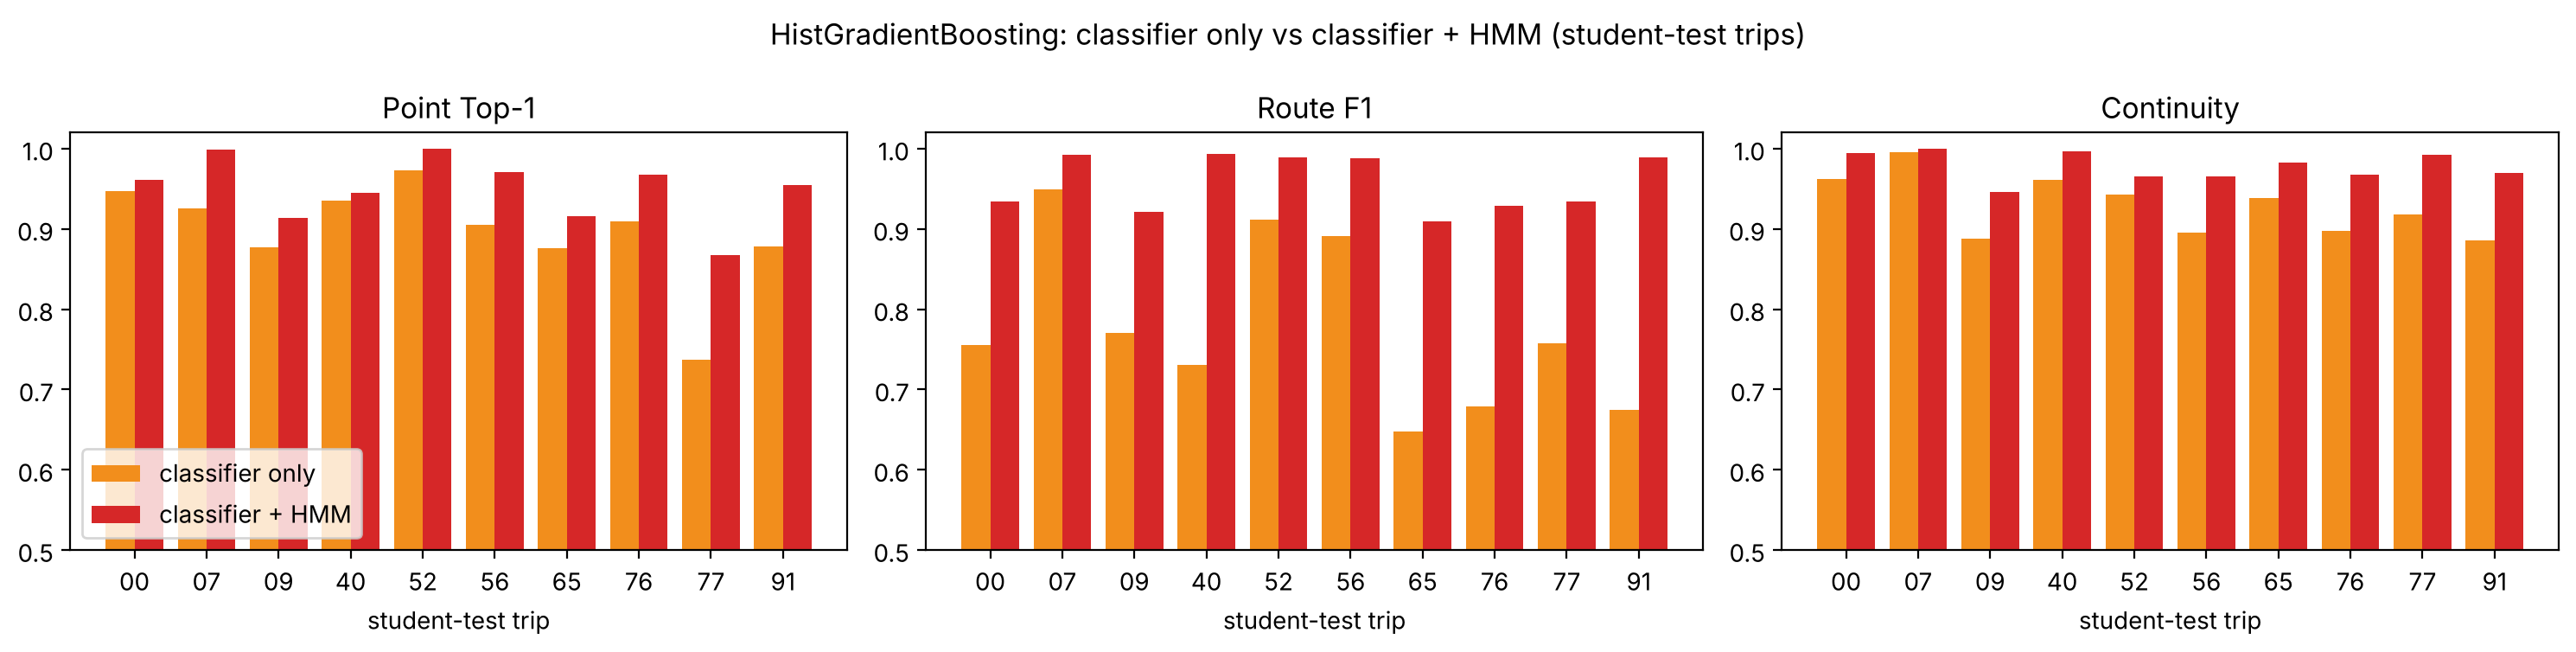

saved results/notebooks/histgb.json


In [6]:
hmm_histgb = nb.hmm_compare(model_histgb, te, "HistGradientBoosting")
nb.plot_hmm(hmm_histgb, "HistGradientBoosting: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("histgb", cv_histgb, train_histgb, test_histgb,
                {"hmm_mean": hmm_histgb.drop(columns=["trip", "model"]).mean().to_dict()})

## LightGBM


**What it does:** gradient boosting with
- **histogram binning**: fast split search
- **leaf-wise growth**: always splits the leaf that reduces the loss most, so it learns fine interactions like *close AND same direction AND neighbours agree*
- row and feature subsampling plus L2 regularisation

Each new tree corrects the previous ones; the final score is the sum of all trees scaled by the learning rate.
- **Why it suits PathSnap:** handles mixed-unit features without scaling, captures interactions, gives well-calibrated probabilities (important for the HMM), and predicts very fast.
- **Limitation:** can overfit with large leaves; it is a black box apart from importances.
- **Hyperparameters (untuned):** n_estimators = 400, learning_rate = 0.05, num_leaves = 63, min_child_samples = 50, subsample = 0.8, colsample_bytree = 0.8, reg_lambda = 1.
- **Loss:** binary log loss.

In [7]:
make_lightgbm = lambda: make_model("lightgbm", SEED)
print(make_lightgbm())
cv_lightgbm = nb.run_cv(make_lightgbm, tr, tr_pts, max_rows=300000)
cv_lightgbm.round(4)

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50,
               n_estimators=400, n_jobs=-1, num_leaves=63, random_state=42,
               reg_lambda=1.0, subsample=0.8, subsample_freq=1, verbose=-1)


  fold 0: F1=0.9159 top1=0.8629 ll=0.1367


  fold 1: F1=0.9314 top1=0.8839 ll=0.0939


  fold 2: F1=0.9242 top1=0.8807 ll=0.1340


  fold 3: F1=0.9523 top1=0.9282 ll=0.0734


  fold 4: F1=0.9148 top1=0.8627 ll=0.1210


CV time 516s | mean macro F1 0.9277 ± 0.0153


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.9159,0.8809,0.8438,0.1367,0.8629,2.2344,0.0588,148.9029
1,0.9314,0.9092,0.8580,0.0939,0.8839,2.4009,0.0771,143.8410
2,0.9242,0.8753,0.8853,0.1340,0.8807,2.2584,0.0522,69.3851
3,0.9523,0.9344,0.9070,0.0734,0.9282,2.4402,0.0708,82.3875
4,0.9148,0.8842,0.8309,0.1210,0.8627,2.3107,0.0680,57.1583


In [8]:
model_lightgbm, train_lightgbm, test_lightgbm, p_lightgbm = nb.fit_and_evaluate(make_lightgbm, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_lightgbm['continuity']:.4f} | inference {test_lightgbm['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("LightGBM", cv_lightgbm, train_lightgbm, test_lightgbm)

fit 75.5s on 300,108 rows
student-test continuity (classifier only): 0.9339 | inference 0.0619 ms/point


LightGBM,train (fit sample),CV mean (5 folds),student test
macro F1,0.9524,0.9277,0.9283
precision,0.9267,0.8968,0.8925
recall,0.9161,0.8650,0.8684
log loss,0.0730,0.1118,0.1039
Top-1 accuracy,0.9242,0.8837,0.8871


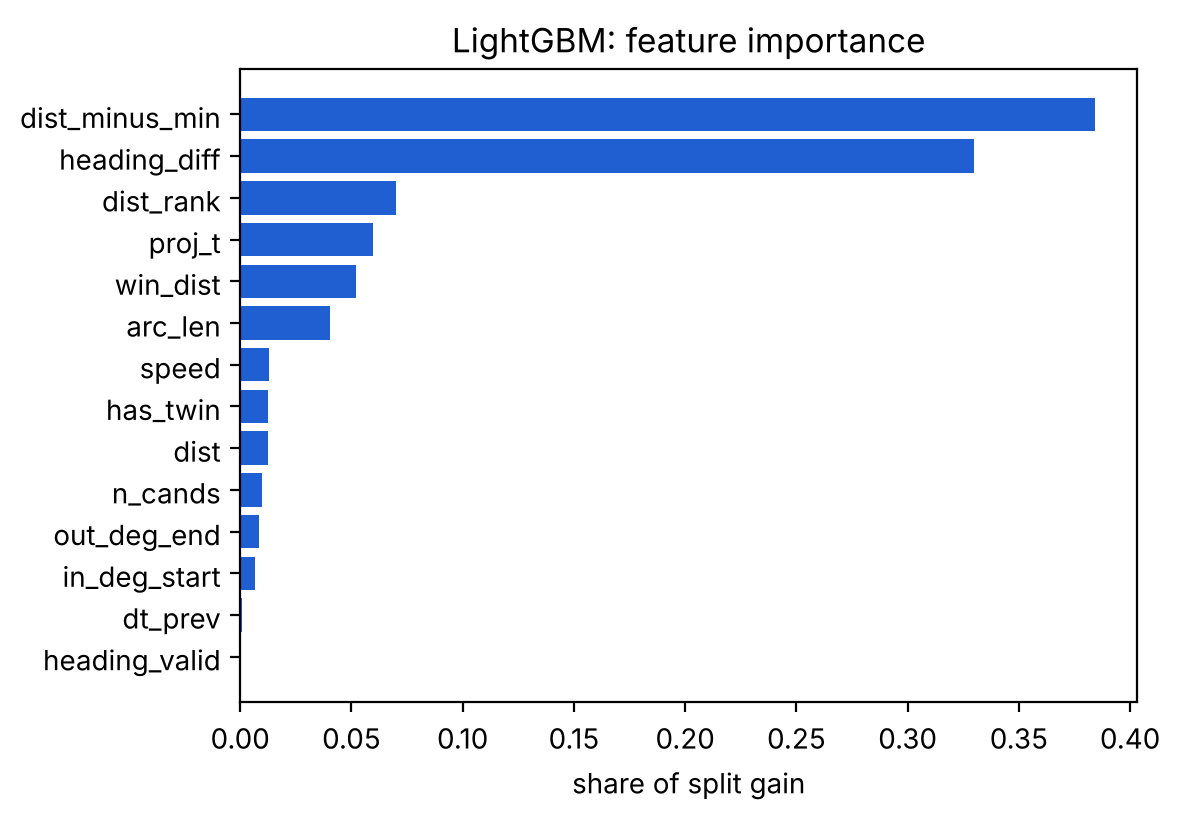

In [9]:
imp_lightgbm = nb.plot_importance(model_lightgbm, te, "LightGBM")

LightGBM: mean over 10 trips
cls_top1          0.9019
hmm_top1          0.9480
cls_route_f1      0.7977
hmm_route_f1      0.9579
cls_continuity    0.9339
hmm_continuity    0.9775


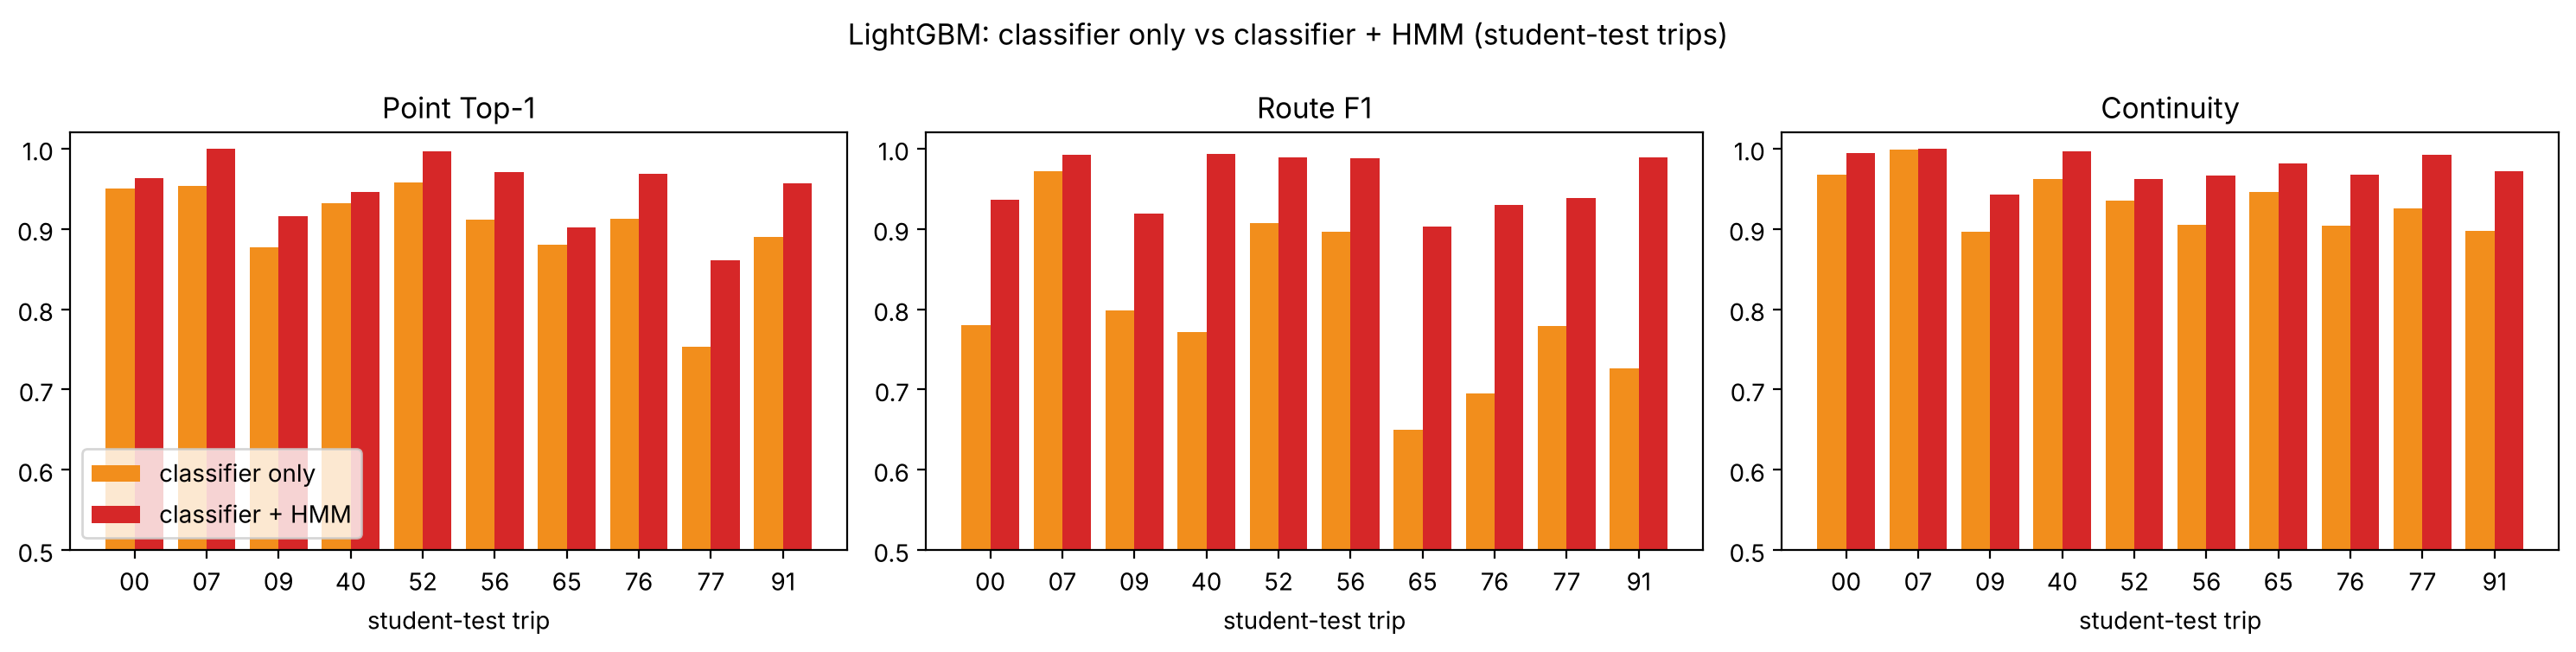

saved results/notebooks/lightgbm.json


In [10]:
hmm_lightgbm = nb.hmm_compare(model_lightgbm, te, "LightGBM")
nb.plot_hmm(hmm_lightgbm, "LightGBM: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("lightgbm", cv_lightgbm, train_lightgbm, test_lightgbm,
                {"hmm_mean": hmm_lightgbm.drop(columns=["trip", "model"]).mean().to_dict()})

### LightGBM training curve
LightGBM records the loss after every boosting round. Here it is trained on 80% of the training trips and validated on the other 20% (a group split by trip) to show how train and validation log loss evolve.

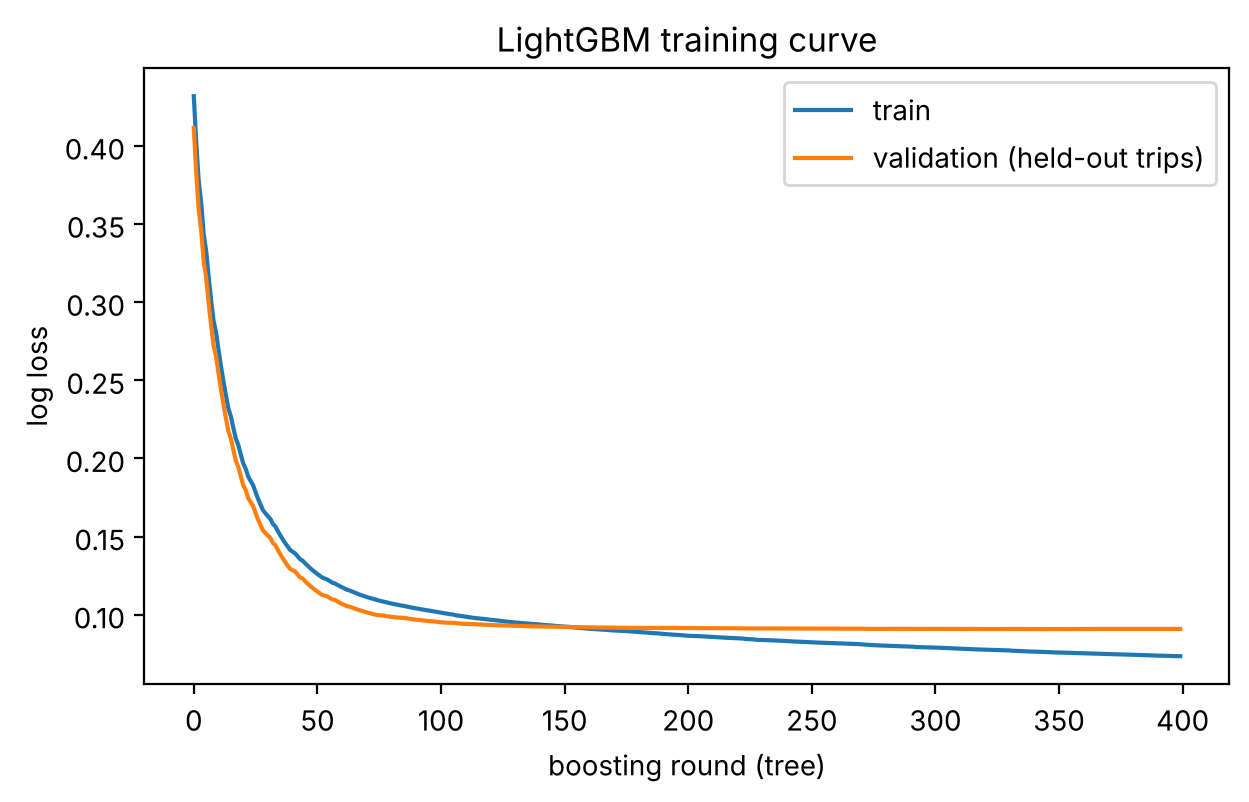

lowest validation log loss 0.0908 at round 344 of 400


In [11]:
from sklearn.model_selection import GroupShuffleSplit
from pathsnap.features import FEATURES
from pathsnap.dataset import subsample_points
i_tr, i_va = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(tr, groups=tr.trip))
fit = subsample_points(tr.iloc[i_tr], 300_000, SEED); va = tr.iloc[i_va]
curve_model = make_model("lightgbm", SEED)
curve_model.fit(fit[FEATURES].to_numpy(), fit.label.to_numpy(),
                eval_set=[(fit[FEATURES].to_numpy(), fit.label.to_numpy()), (va[FEATURES].to_numpy(), va.label.to_numpy())],
                eval_names=["train", "validation"], eval_metric="binary_logloss")
ev = curve_model.evals_result_
plt.figure(figsize=(7, 4))
plt.plot(ev["train"]["binary_logloss"], label="train"); plt.plot(ev["validation"]["binary_logloss"], label="validation (held-out trips)")
plt.xlabel("boosting round (tree)"); plt.ylabel("log loss"); plt.title("LightGBM training curve"); plt.legend(); nb.show()
best = int(np.argmin(ev["validation"]["binary_logloss"]))
print(f"lowest validation log loss {min(ev['validation']['binary_logloss']):.4f} at round {best + 1} of 400")

## Comparison of the models in this notebook

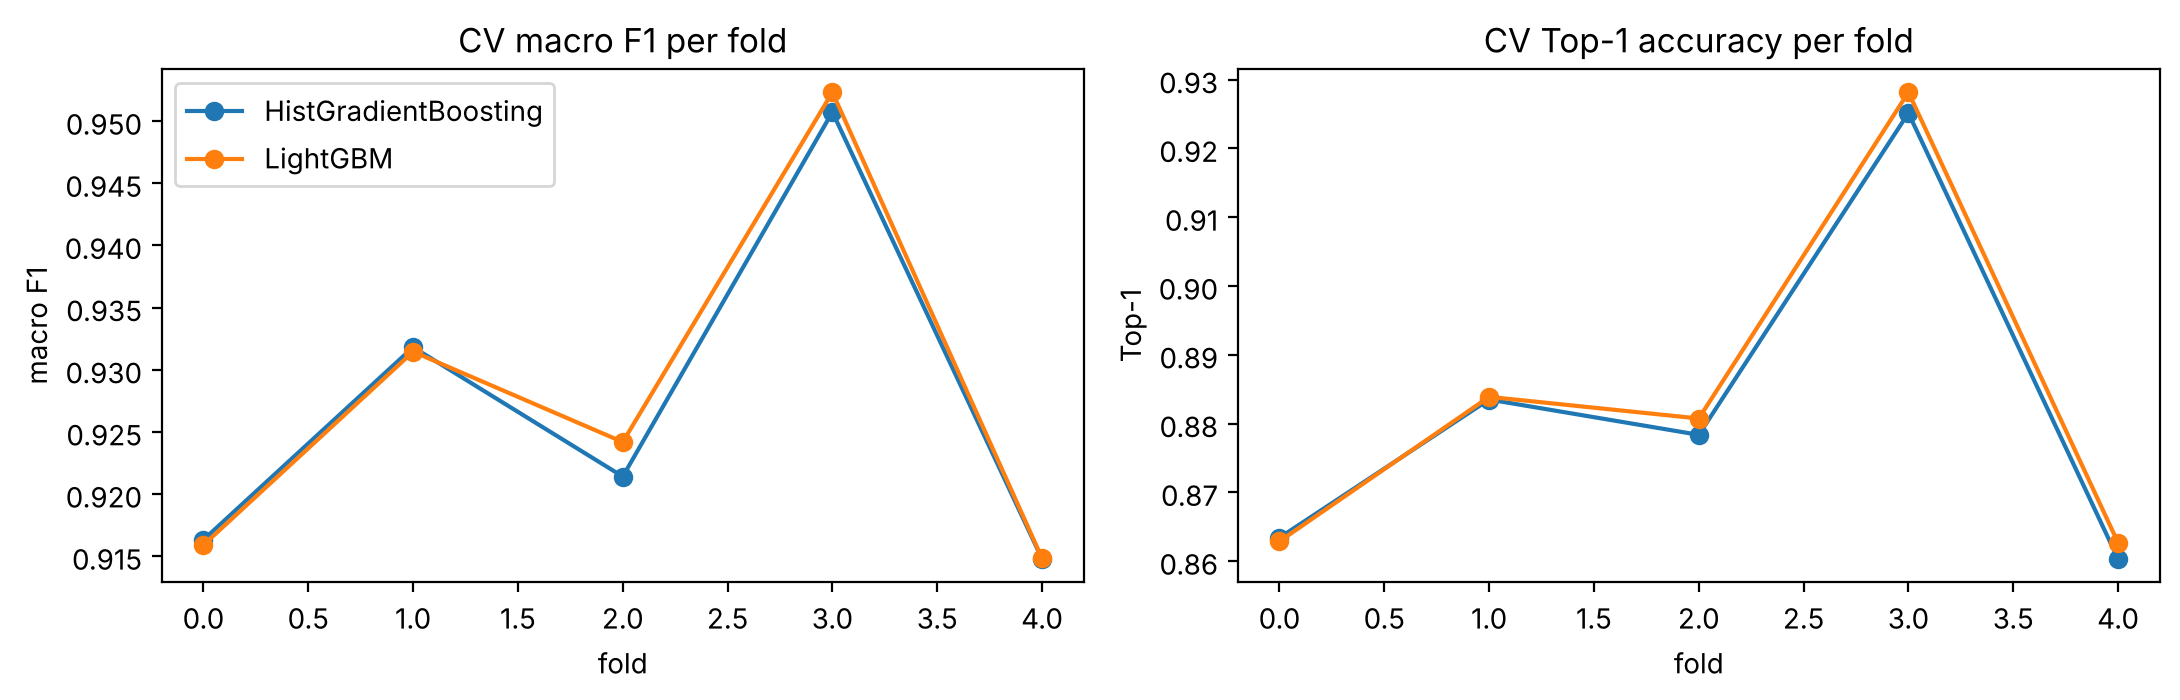

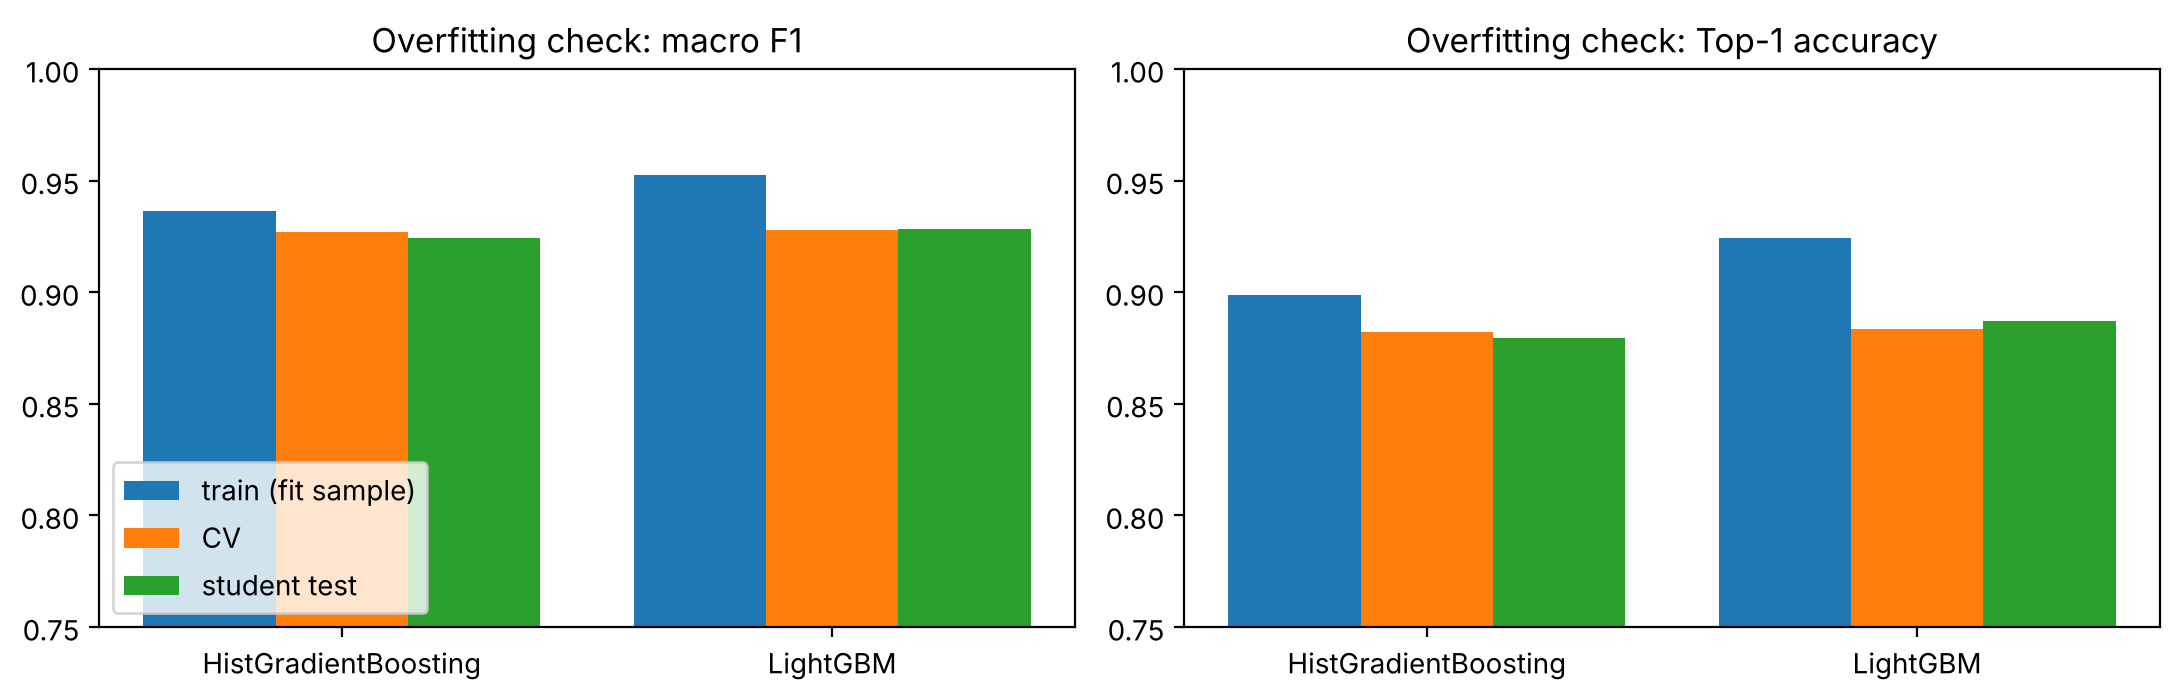

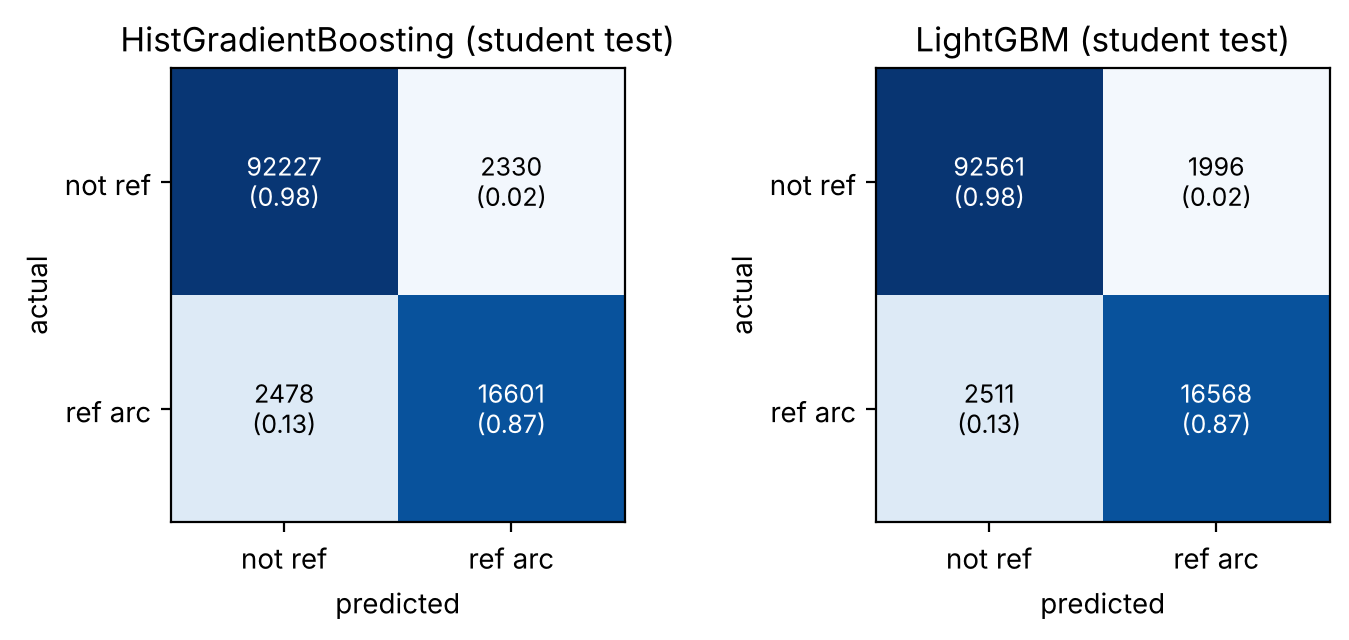

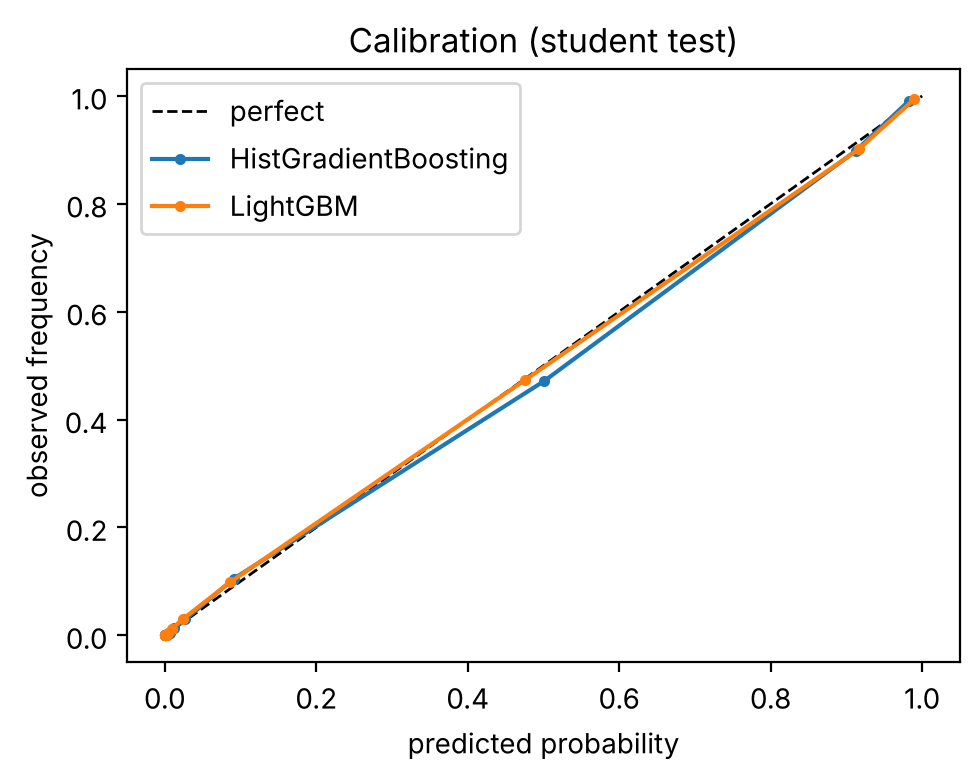

In [12]:
nb.plot_cv_folds({"HistGradientBoosting": cv_histgb, "LightGBM": cv_lightgbm})
nb.plot_overfit({"HistGradientBoosting": (train_histgb, cv_histgb, test_histgb), "LightGBM": (train_lightgbm, cv_lightgbm, test_lightgbm)})
nb.plot_confusion({"HistGradientBoosting": test_histgb["confusion"], "LightGBM": test_lightgbm["confusion"]})
nb.plot_calibration(te.label.to_numpy(), {"HistGradientBoosting": p_histgb, "LightGBM": p_lightgbm})

In [13]:
rows = []
for name, cv, t, h in [("HistGradientBoosting", cv_histgb, test_histgb, hmm_histgb), ("LightGBM", cv_lightgbm, test_lightgbm, hmm_lightgbm)]:
    rows.append({"model": name, "CV macro F1": cv.macro_f1.mean(), "CV std": cv.macro_f1.std(),
                 "test Top-1": t["top1"], "test macro F1": t["macro_f1"], "test log loss": t["log_loss"],
                 "test continuity": t["continuity"], "Top-1 + HMM (trip mean)": h.hmm_top1.mean(),
                 "route F1 + HMM (trip mean)": h.hmm_route_f1.mean()})
pd.DataFrame(rows).set_index("model").round(4)

,CV macro F1,CV std,test Top-1,test macro F1,test log loss,test continuity,Top-1 + HMM (trip mean),route F1 + HMM (trip mean)
model,,,,,,,,
HistGradientBoosting,0.9270,0.0148,0.8796,0.9241,0.1079,0.9285,0.9492,0.9579
LightGBM,0.9277,0.0153,0.8871,0.9283,0.1039,0.9339,0.9480,0.9579
